In [ ]:
# (처음 한 번) 차트에 한글이 보이게 글꼴 설치
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
    plt.rc("font", family="NanumGothic")
    print("한글 글꼴 준비 완료")
except FileNotFoundError:
    print("글꼴 설치 실패 → 차트의 한글이 네모로 보일 수 있어요")
plt.rcParams["axes.unicode_minus"] = False

In [ ]:
# 구글 드라이브 연결
from google.colab import drive
drive.mount('/content/drive')

# 운영체제(OS) 관련 기능 사용
import os

# 작업 위치를 step1 폴더로 이동
os.chdir('/content/drive/MyDrive/Colab Notebooks/Data_Analysis/DA_01')

# 현재 작업 위치 출력
print(os.getcwd())


Mounted at /content/drive
/content/drive/MyDrive/2_Data_analysis_1/step1


In [ ]:
# 데이터 분석에 필요한 라이브러리를 한 번에 불러오기
%run start.py

<Figure size 800x550 with 0 Axes>

In [ ]:
# [수업 포인트] CSV 파일을 읽어서 DataFrame(표)으로 만드는 단계

test = pd.read_csv('data/chick003.csv')
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   hatchery  20 non-null     object
 1   chick_nm  20 non-null     object
 2   weight    20 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 612.0+ bytes


| 컬럼명        | 의미         |
| ---------- | ---------- |
| `hatchery` | 부화장        |
| `chick_nm` | 병아리 번호(이름) |
| `weight`   | 병아리 몸무게    |
컬럼(속성) 3개 : hatchery(부화장), chick_nm(병아리 번호), weight(몸무게)

In [ ]:
print(test)

   hatchery chick_nm  weight
0         A      a01     112
1         A      a05     116
2         A      a09     106
3         A      a12     104
4         A      a15     116
5         A      a17     118
6         A      a26     110
7         A      a28     112
8         A      a29     106
9         A      a30     108
10        B      b01     100
11        B      b02     110
12        B      b07      98
13        B      b11     100
14        B      b13     104
15        B      b17     112
16        B      b22     106
17        B      b27     106
18        B      b28      96
19        B      b30     110


In [ ]:
test.head(3) #  head()는 데이터 앞부분을 빠르게 확인할 때 사용

,hatchery,chick_nm,weight
0,A,a01,112
1,A,a05,116
2,A,a09,106


| 부화장(hatchery) | 병아리 번호(chick_nm) | 몸무게(weight) |
| ------------- | ---------------- | ----------- |
| A             | a01              | 112         |
| A             | a05              | 116         |
| A             | a09              | 106         |


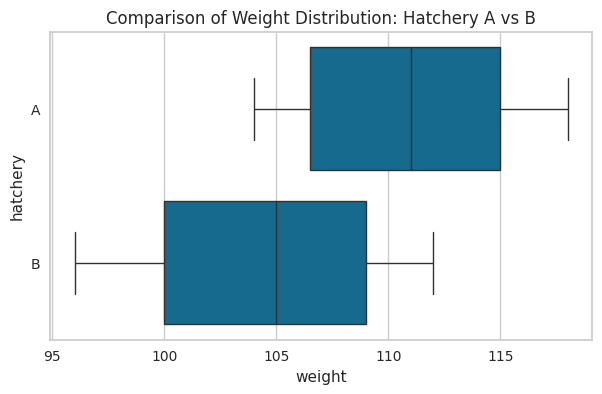

In [ ]:
# matplotlib 라이브러리의 pyplot 사용
# seaborn 라이브러리 사용
# matplotlib.pyplot 라이브러리 함수

plt.figure(figsize=(7,4)) # 그래프 크기 설정
sns.boxplot(x = 'weight', y = 'hatchery', data= test)  # 박스플롯(Box Plot) 생성
plt.title('Comparison of Weight Distribution: Hatchery A vs B', fontsize = 12) # 그래프 제목 설정(부화장 A vs. B   무게 분포 비교)
plt.show() # 그래프 출력

#### t-test (귀무가설 : "두 집단의 평균은 같다")

In [ ]:
# 부화장 A만 별도로 데이터셋 구성
test_a = test.loc[test.hatchery == 'A', 'weight']
test_a

,weight
0,112
1,116
2,106
3,104
4,116
5,118
6,110
7,112
8,106
9,108


In [ ]:
# 부화장 B만 별도로 데이터셋 구성
test_b = test.loc[test.hatchery == 'B', 'weight']
test_b

# 부화장 A에 속한 병아리들의 몸무게만 추출한 결과

,weight
10,100
11,110
12,98
13,100
14,104
15,112
16,106
17,106
18,96
19,110


In [ ]:
import scipy as sp # 통계·과학 계산 라이브러리


Shapiro도 통계 검정의 한 종류이고, t-test도 통계 검정의 한 종류
```
통계 검정
 ├─ Shapiro → 종 모양(정규분포)인가?
 └─ t-test  → 두 그룹 평균이 정말 다른가?
 ```
 Shapiro = 데이터의 모양이 종모양인지 확인 / t-test = 평균 차이 확인

In [ ]:
# 정규분포인지 확인하는 검사 (샤피로 검정)
# 부화장 A 샤피로 윌크 검정 실시 (귀무가설 : 정규분포를 이룬다),
# 기준: 0.05, p값 > 0.05  귀무가설 유지, p값 < 0.05  귀무가설 기각
sp.stats.shapiro(test_a)  # 샤피로-윌크 정규성 검정(데이터가 정규분포(종 모양)를 따르는지 검사)

# p값이 0.553으로 유의수준 0.05보다 크기 때문에 귀무가설 채택(정규분포 OK),
# 이 데이터 정상적인 분포 맞음, 이 데이터 써도 되는지 확인

ShapiroResult(statistic=np.float64(0.9400016973451231), pvalue=np.float64(0.5530322552073004))

| 결과        | 의미                  |
| --------- | ------------------- |
| statistic | 정규분포와 유사한 정도        |
| pvalue    | 정규분포라고 볼 수 있는 확률 기준 |


| 코드                   | 의미             |
| -------------------- | -------------- |
| import scipy as sp | 통계/과학 계산 라이브러리 |
| sp.stats.shapiro() | 정규분포인지 검사      |
| pvalue > 0.05      | 정규분포라고 판단      |
| 현재 결과                | 정규분포에 가까움      |


In [ ]:
# 부화장 B 샤피로 윌크 검정 실시 (귀무가설 : 정규분포를 이룬다)
sp.stats.shapiro(test_b)

# → p값이 0.543으로 유의수준 0.05보다 크기 때문에 귀무가설 채택(정규분포 OK)

ShapiroResult(statistic=np.float64(0.9390683777600799), pvalue=np.float64(0.5426943326835627))

## t-test
- t-test는 두 집단의 평균 차이가 우연히 나온 것인지 통계적으로 확인하는 방법이다.
- 일반적으로 p-value < 0.05이면 '두 집단의 평균이 같다'라는 가정을 버린다.
- 기각 = 처음 세운 가정을 버린다(받아들이지 않는다)
- p-value > 0.05이면 평균이 다르다고 확실하게 말하기 어렵다.
- 그렇다고 '무조건 우연이다'라는 뜻은 아니다.
```
쉽게 말하면
0.05보다 작다 → 두 집단의 평균 차이가 있다고 본다.
0.05보다 크다 → 차이가 있다고 확실히 말하기 어렵다.

In [ ]:
# 두 집단의 평균 차이가 통계적으로 의미 있는지 검정
# 귀무가설 : 두 그룹의 평균은 같다
# p-value < 0.05 → 귀무가설 기각 → 두 그룹의 평균에 유의한 차이가 있음
sp.stats.ttest_ind(test_a, test_b)

TtestResult(statistic=np.float64(2.842528280230058), pvalue=np.float64(0.010803990633924204), df=np.float64(18.0))

| p-value | 의미       |
| ------- | -------- |
| 0.05 이상 | 차이 없다고 봄 |
| 0.05 미만 | 차이 있다고 봄 |


| 개념         | 쉬운 의미         |
| ---------- | ------------- |
| 귀무가설       | 원래는 차이 없다고 가정 |
| T-Test     | 평균 차이 검사      |
| p-value    | 우연일 가능성       |
| p-value 작음 | 진짜 차이 같음      |
| 현재 결과      | A와 B 무게 차이 있음 |


통계 함수 장점
| 장점       | 설명         |
| -------- | ---------- |
| 객관적      | 숫자로 판단     |
| 기준 있음    | p-value 사용 |
| 대용량 가능   | 수만 개도 가능   |
| 논문/연구 가능 | 공식 검증 가능   |


### Shapiro와 t-test를 연결하면
##### Shapiro = 각각의 데이터가 정규분포로 볼 수 있는지 확인 (데이터모양 확인)
##### t-test =  두 그룹의 평균에 의미 있는 차이가 있는지 확인

```
A반 점수 → Shapiro ┐
                    ├→ 정규성 확인 → t-test → A반과 B반 평균 차이 확인
B반 점수 → Shapiro ┘
```
| 순서 | 검정             | 무엇을 확인?        | p-value 기준                  | 쉽게 말하면                |
| -- | -------------- | -------------- | --------------------------- | --------------------- |
| ①  | **Shapiro 검정** | 데이터가 정규분포인지 확인 | **p > 0.05** → 정규분포로 볼 수 있음 | 데이터 모양이 **종 모양인가?**   |
| ↓  |                | **정규성 확인 후**   |                             |                       |
| ②  | **t-test**     | 두 그룹의 평균 차이 확인 | **p < 0.05** → 평균 차이가 유의함   | 두 그룹의 평균이 **정말 다른가?** |
